# M06-5（選讀）| Range learning：把 scale／zero_point 變成可訓練的參數

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m06_qat_pipeline/05_learnable_fake_quant.ipynb)

到目前為止，scale 都由 observer 統計（min／max 的 moving average）決定，訓練只改 weight。
`LearnableFakeQuantize` 把 scale 與 zero_point 做成 `nn.Parameter`，讓 loss 的梯度直接調整量化範圍，也就是 LSQ 的做法。

建議先讀部落格〈[Learning Zero-Point and Scale in Quantization Parameters](https://bobondemon.github.io/2022/12/04/Learning-Zero-Point-and-Scale-in-Quantization-Parameters/)〉，它整理了 LSQ／LSQ+ 怎麼對 scale 與 zero_point 求梯度、grad scaling 是什麼。讀過再看 B 段與 D 段會容易得多。

- **A.** 怎麼接進 PT2E：spec 換成 `LearnableFakeQuantize`；參數要 forward 一次才建立；scale 要夾回正數。
- **B.** 梯度：對 x 仍是 STE；對 scale 的梯度不為零。
- **C.** scale 的軌跡：observer 版 vs learnable 版。
- **D.** 效果（int4、3 個 seed）：observer、learnable、加 grad scaling、qparams 另給 lr。

整本跑完約 2 分鐘。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m06_qat_pipeline")

In [1]:
import copy

import matplotlib.pyplot as plt
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats

from common.data import calibration_batches, evaluate, evaluate_loss, make_loader, trained_tiny_net
from common.graph_utils import observer_nodes, op_counts, sqnr
from common.models import example_inputs
from common.pt2e import (
    LearnableFakeQuantize,
    MovingAverageMinMaxObserver,
    convert_pt2e,
    enable_range_learning,
    export_module,
    prepare_qat_pt2e,
    quiet,
)
from common.qat import EPS, freeze_for_eval, make_schedule, qat_quantizer, train_qat
from common.viz import table

quiet()
_ = torch.manual_seed(0)
set_matplotlib_formats("svg")
BLUE, ORANGE, MUTED, GRID = "#2a78d6", "#eb6834", "#52514e", "#e6e5e1"

## A. 接進 PT2E

`qat_quantizer(weight_fq="learnable", act_fq="learnable")`（`common/qat.py`）只是把 spec 的 `observer_or_fake_quant_ctr` 換成 `LearnableFakeQuantize.with_args(observer=…)`；`prepare_qat_pt2e` 的 conv + BN 子圖、convert 的折疊都照常。

訓練排程：最後 40%（step 96 起）讓 BN 用 running stats，讓最後一段訓練的圖和 convert 圖一致（`make_schedule(bn_eval_at=96)`，本專案 `common/qat.py` 的工具，到了指定的 step 就呼叫 `move_exported_model_to_eval`）；另外在 step 32 呼叫 `enable_range_learning`：先讓 observer 收一個 epoch 的 range 當初始值，再開始學。`enable_range_learning` 會同時關掉 observer，之後 range 只由梯度決定。

In [2]:
model = trained_tiny_net()
test_loader = make_loader(n=1024, seed=2, shuffle=False)
(x,) = next(calibration_batches(64, seed=9))
LEARN_AT = 32


def schedule(learn=True):
    bn = make_schedule(bn_eval_at=96)

    def on_step(step, m):
        bn(step, m)
        if learn and step == LEARN_AT:
            m.apply(enable_range_learning)

    return on_step


def prepare(**kw):
    return prepare_qat_pt2e(export_module(copy.deepcopy(model), example_inputs(), train=True), qat_quantizer(bits=4, **kw))


def n_qparams(gm):
    return sum(1 for n, _ in gm.named_parameters() if n.endswith((".scale", ".zero_point")))


prepared = prepare(weight_fq="learnable", act_fq="learnable")
before = n_qparams(prepared)
with torch.no_grad():
    prepared(*example_inputs())
after = n_qparams(prepared)
print("fake quant 的類別：", {type(m).__name__ for _, m in observer_nodes(prepared)})
print("圖上的 batch_norm（QAT 子圖照常）：", op_counts(prepared).get("batch_norm", 0))
print(f"scale／zero_point 參數：forward 之前 {before} 個，forward 一次之後 {after} 個")
assert before == 0 and after > 0

fake quant 的類別： {'LearnableFakeQuantize'}
圖上的 batch_norm（QAT 子圖照常）： 4
scale／zero_point 參數：forward 之前 0 個，forward 一次之後 24 個


scale／zero_point 是 lazy 建立的：第一次 forward 才由 observer 的統計初始化成 Parameter。optimizer 只記得建立當下已經存在的參數，所以**一定要先 forward 一次再建 optimizer**。`train_qat` 開頭先 forward 一次就是為了這個。

第二個坑要用 M06-3 的檢查才抓得到。`train_qat` 預設在每次 `opt.step()` 之後把 scale 夾回正數（`clamp_scale=True`），下面比較關掉與打開：

In [3]:
rows, a = [], {}
for clamp in (False, True):
    p = train_qat(copy.deepcopy(prepared), epochs=5, on_step=schedule(), seed=1, clamp_scale=clamp)
    converted = convert_pt2e(freeze_for_eval(copy.deepcopy(p)))
    bad = [n.name for n, m in observer_nodes(p) if m.scale is not None and float(m.scale.min()) < EPS]
    with torch.no_grad():
        a[clamp] = sqnr(p(x), converted(x))
    rows.append(["有" if clamp else "無", f"{a[clamp]:.1f}", ", ".join(bad) or "—"])
table(rows, ["每步把 scale 夾回正數", "fake quant 圖 vs convert 圖 (dB)", "scale ≤ 0 的 fake quant"])

每步把 scale 夾回正數,fake quant 圖 vs convert 圖 (dB),scale ≤ 0 的 fake quant
無,6.3,activation_post_process_4
有,inf,—


In [4]:
assert a[False] < 20 and a[True] == float("inf")

- 沒有夾回時，梯度把某些 channel 的 scale 推成負數。forward 照常，因為 $\mathrm{round}(w/s)\cdot s$ 不在乎 $s$ 的正負。會不會推成負數和訓練過程有關：同樣的設定但 BN 不切 eval 時，這裡試的 3 個 seed 都沒有出現負數，所以每步夾回正數是保險的做法。
- torchao 0.18 的 `LearnableFakeQuantize` 只在 `calculate_qparams()`，也就是 convert 取 qparams 時，才把 scale 夾到 eps。那些 channel 的 weight 在 convert 圖裡幾乎全變成 0，兩張圖只剩個位數 dB。
- 每步夾回正數之後（`common/qat.py` 的 `clamp_learnable_scales()`），訓練與 convert 用的是同一個 scale，回到 inf。

## B. 梯度：對 x 是 STE，對 scale 不為零

單獨一個 int4 的 `LearnableFakeQuantize`，用 [-1, 1] 初始化 range 後打開 range learning：

In [5]:
fq = LearnableFakeQuantize(observer=MovingAverageMinMaxObserver, quant_min=-8, quant_max=7, dtype=torch.int8,
                           qscheme=torch.per_tensor_affine, eps=EPS)
with torch.no_grad():
    fq(torch.linspace(-1, 1, 100))
fq.enable_range_learning()
xs = torch.tensor([-3.0, -0.5, 0.0, 0.3, 0.9, 1.5, 4.0], requires_grad=True)
fq(xs).sum().backward()
assert xs.grad is not None and fq.scale is not None and fq.scale.grad is not None
table([["dfq/dx", *(f"{float(g):.0f}" for g in xs.grad)]], ["x", *(f"{float(v):+.1f}" for v in xs)])

x,-3.0,-0.5,+0.0,+0.3,+0.9,+1.5,+4.0
dfq/dx,0,1,1,1,1,0,0


In [6]:
print(f"scale = {float(fq.scale):.4f}，d(sum fq)/d(scale) = {float(fq.scale.grad):.3f}")
assert float(fq.scale.grad) != 0

scale = 0.1333，d(sum fq)/d(scale) = 5.750


對 x 的梯度和 M06-1 一樣是 STE。對 scale 的梯度（LSQ）：range 內是 $\mathrm{round}(x/s) - x/s$，range 外是 $q_{min}$ 或 $q_{max}$。
被 clamp 的值把 scale 往大推，range 內的 round 誤差把 scale 往小推，往哪邊走由 loss 決定，不再由 min／max 決定。
`use_grad_scaling=True` 會把 scale 的梯度除以 $\sqrt{\text{numel} \times q_{max}}$（LSQ 論文的建議），D 段看它的影響。

## C. scale 的軌跡

記錄輸入的 fake quant（`activation_post_process_0`）的 scale，每 32 step 一次：

In [7]:
traj = {}
for name, kw, learn in (("observer", {}, False), ("learnable", dict(weight_fq="learnable", act_fq="learnable"), True)):
    t = []

    def log(step, m, t=t):
        if step % 32 == 0:
            t.append(float(m.get_submodule("activation_post_process_0").calculate_qparams()[0]))

    train_qat(prepare(**kw), epochs=5, on_step=schedule(learn), seed=1, log=log)
    traj[name] = t
STEPS = list(range(32, 161, 32))

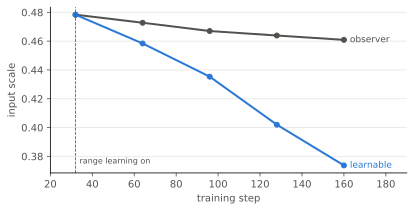

In [8]:
#| code-fold: true
#| code-summary: 畫圖的程式
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for (name, t), color in zip(traj.items(), (MUTED, BLUE)):
    ax.plot(STEPS, t, color=color, lw=2, marker="o", ms=5)
    ax.annotate(name, (STEPS[-1], t[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=color, fontsize=9)
ax.axvline(LEARN_AT, color=MUTED, lw=0.8, ls="--")
ax.annotate("range learning on", (LEARN_AT, min(min(t) for t in traj.values())), xytext=(4, 0),
            textcoords="offset points", color=MUTED, fontsize=8, va="bottom")
ax.set_xlim(20, 190)
ax.set_xlabel("training step", color=MUTED)
ax.set_ylabel("input scale", color=MUTED)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
plt.show()

In [9]:
assert traj["learnable"][-1] < traj["observer"][-1]

observer 版的 scale 只隨 moving average 慢慢漂；learnable 版從 step 32 起被梯度持續往小推：縮小 range 換取 range 內更細的格子，代價是更多值被 clamp。

## D. 效果

int4、lr 1e-3、BN eval @96，每個設定 3 個 seed。評估用 freeze 之後的 fake quant 圖（A 段已確認和 convert 圖相同）：

In [10]:
CONFIGS = {
    "observer（不學 range）": ({}, {}),
    "learnable": (dict(weight_fq="learnable", act_fq="learnable"), {}),
    "learnable + grad scaling": (dict(weight_fq="learnable", act_fq="learnable", grad_scaling=True), {}),
    "learnable + grad scaling，qparams lr 1e-2": (dict(weight_fq="learnable", act_fq="learnable", grad_scaling=True),
                                                 dict(qparams_lr=1e-2)),
    "learnable，qparams lr 1e-2（沒有 grad scaling）": (dict(weight_fq="learnable", act_fq="learnable"), dict(qparams_lr=1e-2)),
}
d = {}
for name, (qkw, tkw) in CONFIGS.items():
    base, losses, accs = prepare(**qkw), [], []
    for seed in (1, 2, 3):
        p = freeze_for_eval(train_qat(copy.deepcopy(base), epochs=5, on_step=schedule(name != "observer（不學 range）"),
                                      seed=seed, **tkw))
        losses.append(evaluate_loss(p, test_loader))
        accs.append(evaluate(p, test_loader))
    d[name] = (losses, sum(accs) / 3)
table([[name, f"{sum(v) / 3:.3f}", f"{min(v):.3f} ~ {max(v):.3f}", f"{acc:.3f}"] for name, (v, acc) in d.items()],
      ["設定", "test loss 平均", "min ~ max", "accuracy 平均"])

設定,test loss 平均,min ~ max,accuracy 平均
observer（不學 range）,0.883,0.838 ~ 0.947,0.712
learnable,0.757,0.750 ~ 0.767,0.722
learnable + grad scaling,0.840,0.753 ~ 0.941,0.721
learnable + grad scaling，qparams lr 1e-2,0.806,0.727 ~ 0.865,0.695
learnable，qparams lr 1e-2（沒有 grad scaling）,1.395,1.386 ~ 1.413,0.247


In [11]:
obs, learn = d["observer（不學 range）"][0], d["learnable"][0]
gs = d["learnable + grad scaling"][0]
# 前四種設定誰最好，取決於平台與 seed（見下方說明）；只有發散這一條是穩定的
assert d["learnable，qparams lr 1e-2（沒有 grad scaling）"][1] < 0.3  # 發散：accuracy 接近 4 類的隨機猜測

- **換成 learnable（其他不動）**：在這本 notebook 最初撰寫的 macOS arm64 上，3 個 seed 都優於 observer 版，seed 間的範圍也最窄。在 Linux x86 上重跑，平均並沒有比 observer 版好，seed 間的範圍反而最寬：range learning 有沒有幫助，取決於平台與 seed。
- **加上 grad scaling**：scale 的梯度變小、走得慢。在 macOS arm64 上平均變差、範圍變寬；在 Linux x86 上則得到最好的平均與較窄的範圍。再把 qparams 的 lr 調大，在 Linux x86 上沒有幫助。
- **沒有 grad scaling 又給 qparams lr 1e-2**：直接發散，accuracy 掉到 4 類的隨機猜測（兩個平台都是）。scale 的 lr 和 grad scaling 綁在一起，只能一起調。
- 這是單一模型、3 個 seed 的結果，而且前四種設定的排名在兩個平台間翻轉了，所以它們之間這種大小的差異屬於雜訊；「不開 grad scaling 比較好」（或相反）在其他模型上是否成立，這裡沒有驗證。